In [1]:
from langchain_ollama import ChatOllama,OllamaEmbeddings
from typing import TypedDict
from dotenv import load_dotenv
from langgraph.graph import StateGraph,START,END
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pydantic import BaseModel,Field
from langchain_community.vectorstores import Chroma, FAISS
import re
import os

load_dotenv()
print("Tavily key:", bool(os.getenv("TAVILY_API_KEY")))



/tmp/ipykernel_36055/2762554765.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


Tavily key: True


In [2]:
llm = ChatOllama(model='qwen2.5:1.5b',temperature=0.2)
embeddings = OllamaEmbeddings(model="nomic-embed-text")

In [3]:
docs = (
    # PyPDFLoader("documents/book1.pdf").load() +
    # PyPDFLoader("documents/book2.pdf").load() +
    PyPDFLoader("documents/book3.pdf").load()
)


chunks = RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=200).split_documents(documents=docs)
for d in chunks:
    d.page_content = d.page_content.encode('utf-8','ignore').decode('utf-8','ignore')
print("========> Text splitting done")

========> Text splitting done


In [5]:
vector_store = FAISS.from_documents(documents=chunks,embedding=embeddings)
retriever = vector_store.as_retriever(search_type='similarity',search_kwargs={'k':4})

print(" ====> Embeddings stored ")

KeyboardInterrupt: 

In [6]:

UPPER_TH = 0.7
LOWER_TH = 0.3


class State(TypedDict):
    question: str
    docs :list[Document]

    good_docs: list[Document]
    verdict: str
    reason: str 

    strips: list[str]
    kept_strips: list[str]
    refined_context: str

    web_docs: list[Document]

    answer: str


def retrieve_node(state:State):
    q = state['question']
    return {'docs':retriever.invoke(q)}


class DocEvalScore(BaseModel):
    score:float
    reason: str


doc_eval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            'system',
            "You are a strict retrieval evaluator for RAG. \n"
            "You will be given one retrieved chunk and a question. \n"
            "Return a relevance score in [0.0, 1.0]. \n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly. \n"
            "- 0.0: chunk is irrelevant.\n"
            "Be conservative with high scores.\n"
            "Also return a short reason.\n"
            "Output JSON only."
        ),
        (
            'human',
            "Question: {question} \n\n Chunk: {chunk}"
        )
    ]
)

doc_eval_chain = doc_eval_prompt | llm.with_structured_output(DocEvalScore)

def eval_each_doc_node(state:State):
    q = state['question']
    scores:list[float] = []
    good: list[Document] = []

    for d in state['docs']:
        out = doc_eval_chain.invoke({'question':q,'chunk':d.page_content})
        scores.append(out.score)
        if out.score > LOWER_TH:
            good.append(d)

    if any(s > UPPER_TH for s in scores):
        return {
            'good_docs':good,
            'verdict':'CORRECT',
            'reason':f'At least one retrieved chunk has score > {UPPER_TH}'
        }

    if len(scores) > 0 and all(s < LOWER_TH for s in scores):
        return {
            'good_docs':[],
            'verdict':'INCORRECT',
            'reason':f'All retrieved chunks scored < {LOWER_TH}, No chunk was sufficient.'
        }
    
    return {
        'good_docs':good,
        'verdict':'AMBIGUOUS',
        'reason':f'No chunk scored > {UPPER_TH}, but not all were < {LOWER_TH}. Mixed relevance signals.'
    }


def decompose_to_sentences(text:str):
    text = re.sub(r"\s"," ",text).strip()
    sentences = re.split(r"(?<=[.!?])\s+",text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]


class KeepOrDrop(BaseModel):
    keep:bool


filter_prompt = ChatPromptTemplate.from_messages(
    [
        (
            'system',
            "You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use only the sentence.\n"
            "Output JSON only."
        ),
        (
            'human',
            "Question: {question}\n\nSentence: {sentence}"
        )
    ]
)


filter_chain = filter_prompt | llm.with_structured_output(KeepOrDrop)


def refine(state:State):
    q = state['question']

    if state.get('verdict') == 'CORRECT':
        context = '\n\n'.join(d.page_content for d in state['good_docs']).strip()
    else:
        context = '\n\n'.join(d.page_content for d in state['web_docs']).strip()

    strips = decompose_to_sentences(context)

    kept: list[str] = []
    for s in strips:
        if filter_chain.invoke({'question':q,'sentence':s}).keep:
            kept.append(s)

    refined_content = '\n'.join(kept).strip()
    return {
        'strips':strips,
        "kept_strips":kept,
        "refined_content":refined_content
    }


tavily = TavilySearchResults(max_results=5)

def web_seach_node(state:State):
    q = state['question']
    results = tavily.invoke({'query':q})

    web_docs = []
    for r in results or []:
        title = r.get('title',"")
        url = r.get('url',"")
        content = r.get('content','')
        text = f'TITLE: {title}\n URL: {url}\n CONTENT: {content}'
        web_docs.append(Document(page_content=text, metadata={'url':url,"title":title}))

    return {'web_docs':web_docs}


answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            'system',
            "You are a helpful ML tutor. "
            "Answer ONLY using the provided context.\n"
            "If the context is empty or insufficient, say: I don't know."
        ),
        (
            'human',
            "Question: {question}\n\nRefined_Context: {refined_context}"
        )
    ]
)


def generate(state:State):
    out = (answer_prompt | llm).invoke(
        {'question':state['question'],'refined_context':state['refined_context']}
    )
    return {'answer':out.content}


def ambiguous_node(state:State):
    return {'answer':f"Ambiguous: {state['reason']}"}

def router_after_eval(state:State):
    if state['verdict'] == 'CORRECT':
        return "refine"
    elif state['verdict'] == 'INCORRECT':
        return 'web_search'
    else:
        return 'ambiguous'


g = StateGraph(State)

g.add_node('retrieve',retrieve_node)
g.add_node('eval_each_doc',eval_each_doc_node)
g.add_node('web_search',web_seach_node)
g.add_node('refine',refine)
g.add_node('generate',generate)
g.add_node('ambiguous',ambiguous_node)

g.add_edge(START,'retrieve')
g.add_edge('retrieve','eval_each_doc')
g.add_conditional_edges(
    'eval_each_doc',
    router_after_eval,
    {'refine':'refine','web_search':'web_search','ambiguous':'ambiguous'}
)
g.add_edge('web_search','refine')
g.add_edge('refine','generate')
g.add_edge('generate',END)
g.add_edge('ambiguous',END)

app = g.compile()

print(app.get_graph().draw_ascii())






                        +-----------+                         
                        | __start__ |                         
                        +-----------+                         
                              *                               
                              *                               
                              *                               
                        +----------+                          
                        | retrieve |                          
                        +----------+                          
                              *                               
                              *                               
                              *                               
                      +---------------+                       
                      | eval_each_doc |                       
                     .+---------------+.                      
                 ....         .         .....          

/tmp/ipykernel_36055/2123054383.py:139: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults(max_results=5)


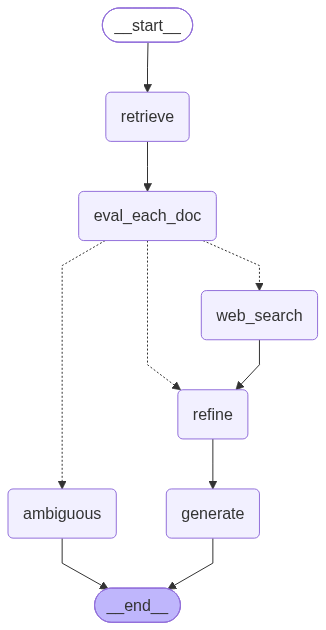

In [7]:
app

In [8]:

res = app.invoke({
    'question': "Ai news from the last month",
    "docs":[],
    "good_docs":[],
    "verdict": "",
    "reason":'',
    'strips':[],
    'kept_strips':[],
    'refined_context':'',
    'web_docs': [],
    'answer':''
})



print(res)


NameError: name 'retriever' is not defined